# --------------------------------------------------------------
# Code for 4 tank example: MS-DeepONet architecture
# --------------------------------------------------------------
## This notebook includes:
 - Input signal generation (multisine)
 - Simulation of 4 tank Dynamics and data generation  
 - MS-DeepONet prediction model learning using pytorch
 - Model Predictive Control (MPC) simulation using CasADi
# --------------------------------------------------------------

### Import required packages

In [5]:
# Standard libraries
import time
import itertools
import sys

# Scientific computing
import numpy as np
import pandas as pd
from scipy.integrate import solve_ivp
from scipy.io import savemat

# Plotting
import matplotlib.pyplot as plt

# Deep learning
import torch
import torch.nn.functional as F
import models  # your custom model module

# Optimization (solving the MPC problem)
import casadi as ca

# Functions used in scripts
from functions import four_tank, NN, multisine
 

### Generate input signal used for model learning

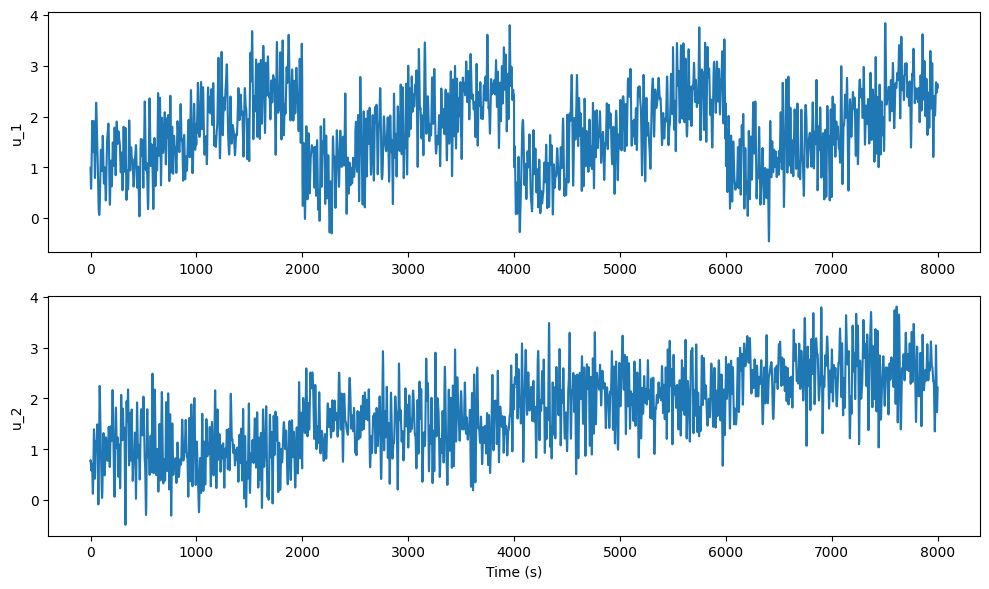

In [6]:
# Generate piecewise constanrt reference for u1
u1_data1 =  np.tile([1.000], (500, 1))
u1_data2 =  np.tile([1.500], (500, 1))
u1_data3 =  np.tile([2.000], (500, 1))
u1_data4 =  np.tile([2.500], (500, 1))

u1_data_all = np.concatenate((u1_data1, u1_data2, u1_data3, u1_data4), axis=0)
u1_data_all = np.concatenate((u1_data_all, u1_data_all, u1_data_all, u1_data_all), axis=0)

# Generate piecewise constanrt reference for u2
u2_data1 =  np.tile([1.000], (2000, 1))
u2_data2 =  np.tile([1.500], (2000, 1))
u2_data3 =  np.tile([2.000], (2000, 1))
u2_data4 =  np.tile([2.500], (2000, 1))
u2_data_all = np.concatenate((u2_data1, u2_data2, u2_data3, u2_data4), axis=0)

# Add multisine to piecewise constant signals
u_data_1_additional = 0.5*multisine(N_points_per_period=8000, N_periods=1, pmin=1, pmax=500, n_crest_factor_optim=100,seed=42)
u_data_2_additional = 0.5*multisine(N_points_per_period=8000, N_periods=1, pmin=1, pmax=500, n_crest_factor_optim=100,seed=36)
u1_data = u1_data_all + u_data_1_additional.reshape(-1, 1)
u2_data = u2_data_all + u_data_2_additional.reshape(-1, 1)
u_data = np.hstack((u1_data,u2_data))

# Plot the final input signal which will be used to generate the data
plt.figure(figsize=(10, 6))
plt.subplot(2, 1, 1)
plt.plot(u1_data)
plt.ylabel('u_1')
plt.subplot(2, 1, 2)
plt.plot(u2_data)
plt.ylabel('u_2')
plt.xlabel('Time (s)')
plt.tight_layout()
plt.show()

### Generate output data for the van der 4tank, used for training

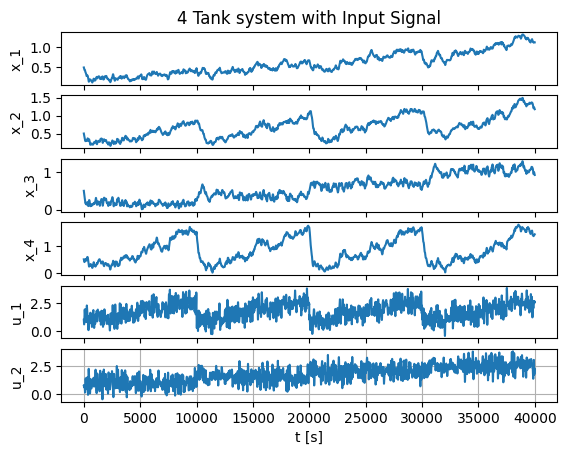

In [8]:
# Model parameters
N = 20 # prediction horizon of the controller
Ts = 5 # Sampling time of the controller
a1, a2, a3, a4 = 1.31e-4, 1.51e-4, 9.27e-5, 8.82e-5
gamma_a, gamma_b = 0.3, 0.4
g, Sc = 9.81, 0.06
params = {'a1': a1, 'a2': a2, 'a3': a3, 'a4': a4, 'gamma_a': gamma_a, 'gamma_b': gamma_b, 'g': g, 'Sc': Sc}

x0 = np.array([0.5, 0.5, 0.5, 0.5])  # Initial conditions: [h1, h2, h3, h4]
t_vec = [0]
x = [x0]

# Main loop
for i in range(len(u1_data)):
    u1 = float(u1_data[i].item())
    u2 = float(u2_data[i].item())
    sol = solve_ivp(lambda t, y: four_tank(t, y, u1, u2, params),[0, Ts], x0, method='RK45')
    x0 = sol.y[:, -1]
    x.append(x0)  # store state
    t_vec.append((i+1) * Ts)  # store time

# Convert list to numpy array 
x = np.array(x)
t_vec = np.array(t_vec)


# Plotting
plt.subplot(6,1,1)
plt.plot(t_vec, x[:, 0], label='x_1')
plt.title('4 Tank system with Input Signal')
plt.ylabel('x_1')
plt.subplot(6,1,2)
plt.plot(t_vec, x[:, 1], label='x_2')
plt.ylabel('x_2')
plt.subplot(6,1,3)
plt.plot(t_vec, x[:, 2], label='x_3')
plt.ylabel('x_3')
plt.subplot(6,1,4)
plt.plot(t_vec, x[:, 3], label='x_4')
plt.ylabel('x_4')
plt.subplot(6,1,5)
plt.plot(t_vec[0:len(u1_data)], u1_data, label='u_1')
plt.ylabel('u_1')
plt.subplot(6,1,6)
plt.plot(t_vec[0:len(u2_data)], u2_data, label='u_2')
plt.ylabel('u_2')
plt.xlabel('t [s]')
plt.grid()
plt.show()

### Generate Hankel matrices used for model learning

In [9]:
# Initialze empty data matrices
U = [] # Input data matrix
X0 = [] # Initial condition data matrix
Y = [] # Output data matrix
T = len(u_data) # Length of the input signal 

# For loop for generating Hankel matrices
for i in range(T - N):
    for j in range(N):
        if j == 0:
            Y_i = x[i + j + 1,:] # Initialize intermediate output data matrix
            U_i = u_data[i + j ,:] # Initialize intermediate input data matrix  
        else:
            Y_i = np.hstack((Y_i,x[i + j + 1,:])) # Append Y_i with output
            U_i = np.hstack((U_i,u_data[i + j,:]))  # Append U_i with input
    if i == 0:
        Y = Y_i  # Initialize output data matrix
        U = U_i  # Initialize input data matrix  
    else:
        Y = np.vstack((Y,Y_i)) # Append Y with output vector
        U = np.vstack((U,U_i)) # Append U with input vector

    # Initial state at time i
    X0.append(x[i,:])  # Append X0 with initial conditions


# Convert to numpy arrays 
U = np.array(U)      
X0 = np.array(X0)    
Y = np.array(Y)      

# Divide Data sets into training and validation 
U_train = U[0:7500,:]
U_test = U[7500:,:]
X0_train = X0[0:7500,:]
X0_test = X0[7500:,:]
Y_train = Y[0:7500,:]
Y_test = Y[7500:,:]

# Optional: print shapes
print("Shapes after split:")
print(f"U_train: {U_train.shape}, U_test: {U_test.shape}")
print(f"X0_train: {X0_train.shape}, X0_test: {X0_test.shape}")
print(f"Y_train: {Y_train.shape}, Y_test: {Y_test.shape}")

Shapes after split:
U_train: (7500, 40), U_test: (480, 40)
X0_train: (7500, 4), X0_test: (480, 4)
Y_train: (7500, 80), Y_test: (480, 80)


### Train the MS-DeepONet model 

In [10]:
# Define the network dimensions
ld_list = [20] # Neurons in output layer, change to [20,30,...] to train for multiple combinations
neuron_list = [40] # Neurons per hidden layer, change to [20,30,...] to train for multiple combinations
layer_list = [1] # number of hidden layers, change to [2,3,...] to train for multiple combinations
N_epoch = 400 # Number of epochs used for training the model
N_comb_val = len(ld_list)*len(neuron_list)*len(layer_list) # Total number of hyperparameter configurations to train for

# make sure that GPU is used when available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Convert training data to tensors
trunk_input_train = torch.tensor(X0_train, dtype=torch.float32).to(device)
branch_input_train = torch.tensor(U_train, dtype=torch.float32).to(device)
output_train = torch.squeeze(torch.tensor(Y_train, dtype=torch.float32).to(device))

# Convert validation data to tensors
trunk_input_val = torch.tensor(X0_test, dtype=torch.float32).to(device)
branch_input_val = torch.tensor(U_test, dtype=torch.float32).to(device)
output_val = torch.squeeze(torch.tensor(Y_test, dtype=torch.float32).to(device))

# Network and data dimensions
B_train = len(trunk_input_train[:,0]) # Batch size for training data
B_val = len(trunk_input_val[:,0]) # Batch size for validation data
nx = len(trunk_input_train[0,:]) # Input dimension Trunk net
Nnu = len(branch_input_train[0,:]) # Input dimension Branch net
Nny = len(output_train[0,:]) # Output dimension network

# Define the training loop using pytorch 
def train(idx,neuron,layer,ld,loss_val_i,niter,N_comb):
    # Define the Branch network:
    branch = models.MLP(
        layers=[Nnu] + [neuron] * layer + [ld*Nny],
        activation=F.tanh,
    ).to(device)

    # Define the Trunk network:
    trunk = models.MLP(layers=[nx] + [neuron] * layer + [ld], activation=F.tanh).to(device)

    # Define the optimizer, learning rate, weight decay
    optimizer = torch.optim.AdamW(
        list(branch.parameters()) + list(trunk.parameters()), 
        lr=1e-3, # Learning rate
        weight_decay=1e-4  # L2 regularization (weight decay)
    )

    # Add a learning rate scheduler that reduces the learning rate by a factor of gamma every step_size iterations
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10000, gamma=0.1)

    # Initialize empty list for storing the training and validation loss
    train_loss_hist = []
    val_loss_hist = []
    t0 = time.time()
    # training loop
    for i in range(niter):
        # Training step
        def train_step():
            optimizer.zero_grad() # reset the gradients    
            # Forward pass:     
            b_out = branch(branch_input_train) # Branch net forward pass
            t_out = trunk(trunk_input_train) # Trunk net forward pass
            b_out = b_out.reshape(B_train, Nny, ld) # convert Branch net output layer into matrix
            u_pred = torch.einsum("bij,bj->bi", b_out, t_out) # Product layer
            loss = torch.mean((u_pred - output_train) ** 2) / torch.mean((output_train) ** 2) # Calculate training loss 
            # Backward pass
            loss.backward() 
            # Update parameters
            optimizer.step() 
            return loss
        
        # Validation step
        def validation_step():
             with torch.no_grad():               
                b_out = branch(branch_input_val)
                t_out = trunk(trunk_input_val)
                b_out = b_out.reshape(B_val, Nny, ld)
                u_pred = torch.einsum("bij,bj->bi", b_out, t_out)
                loss = torch.mean((u_pred - output_val) ** 2) / torch.mean((output_val) ** 2)
                return loss

        loss_train = train_step() # Perform a training step (includes forward pass, loss calc, backward pass, optimizer step)
        loss_val = validation_step() # Perform a validation step (forward pass + loss calc, no weight updates)
        l_train = loss_train.detach().cpu().numpy() # Move training loss tensor to CPU, detach from graph, convert to NumPy
        l_val = loss_val.detach().cpu().numpy() # Same as above for validation loss

        train_loss_hist.append(l_train) # Append training loss data 
        val_loss_hist.append(l_val) # Append validation loss data 

        current_lr = optimizer.param_groups[0]['lr'] # Get the current learning rate from the optimizer
        current_lr = round(current_lr, 5) # Round the learning rate to 5 decimal places for printing
        
        # Print usefull information during training:
        if i % 10 == 0:
            print(
                "index: ",
                idx,
                "/ ",
                N_comb,
                " Epoch: ",
                i + 1,
                "Learning rate: ",
                current_lr,
                "Train loss",
                l_train,
                "Val loss",
                l_val,
                flush=True,
            )
        # Save the model every 100 iterations and only when validation loss has decreased
        if i % 100 == 0 and loss_val_i >= l_val:
            loss_val_i = l_val
            l_indx_i = i
            torch.save(branch, "data_MS/kan_mlp_branch_idx_{}".format(str(int(idx))))
            torch.save(trunk, "data_MS/kan_mlp_trunk_idx_{}".format(str(int(idx))))

        # Step the learning rate scheduler at the end of each iteration
        scheduler.step()
        
    t1 = time.time()
    print("Total time: ", t1 - t0, flush=True)
    t_elapsed = t1 - t0

    # Save training and validation losses
    np.save("data_MS/train_loss.npy", train_loss_hist, allow_pickle=True)
    np.save("data_MS/val_loss.npy", val_loss_hist, allow_pickle=True)

    return np.array(train_loss_hist), np.array(val_loss_hist), l_indx_i, loss_val_i, t_elapsed


# start of the ablation study 
ablation_results = [] # Initialize empty list for storing the ablation results 
combinations = itertools.product(ld_list,neuron_list,layer_list) # Generate set of hyperparameter configurations for ablation study 
idx_i = 0 # Initialize training index 

# Looping through the range of indices (1 to idx_total-1 in this case, but you can extend it)
for ld_i, neuron_i, layer_i in combinations:
    idx_i += 1
    # Call the train function with the current index
    train_loss_hist_i, val_loss_hist_i, l_indx_opt, loss_val_opt, t_elapsed   = train(idx=idx_i,ld=ld_i,neuron=neuron_i,layer=layer_i,loss_val_i=float('inf'),niter=N_epoch,N_comb = N_comb_val)
    
    # Create a dictionary to store the ablation results
    results = {
        'idx': idx_i,
        'neurons output layer': ld_i,
        'neurons hidden per layer': neuron_i,
        'hidden layers': layer_i,
        'training loss': train_loss_hist_i,
        'validation loss': val_loss_hist_i,
        'training time': t_elapsed
    }
    
    # Append the results to the ablation_results list
    ablation_results.append(results)


Using device: cpu
index:  1 /  1  Epoch:  1 Learning rate:  0.001 Train loss 1.1488562 Val loss 0.89565617
index:  1 /  1  Epoch:  11 Learning rate:  0.001 Train loss 0.14412257 Val loss 0.051296867
index:  1 /  1  Epoch:  21 Learning rate:  0.001 Train loss 0.0634311 Val loss 0.05844115
index:  1 /  1  Epoch:  31 Learning rate:  0.001 Train loss 0.028397325 Val loss 0.027298106
index:  1 /  1  Epoch:  41 Learning rate:  0.001 Train loss 0.018129967 Val loss 0.009784534
index:  1 /  1  Epoch:  51 Learning rate:  0.001 Train loss 0.012262139 Val loss 0.007003301
index:  1 /  1  Epoch:  61 Learning rate:  0.001 Train loss 0.00913538 Val loss 0.0043189903
index:  1 /  1  Epoch:  71 Learning rate:  0.001 Train loss 0.0075054374 Val loss 0.004231374
index:  1 /  1  Epoch:  81 Learning rate:  0.001 Train loss 0.006476817 Val loss 0.0035635415
index:  1 /  1  Epoch:  91 Learning rate:  0.001 Train loss 0.0057291985 Val loss 0.0030039807
index:  1 /  1  Epoch:  101 Learning rate:  0.001 Train 

### Convert the ablation results to a .mat file for analysis with MATLAB

Text(0.5, 1.0, 'Training and validation loss')

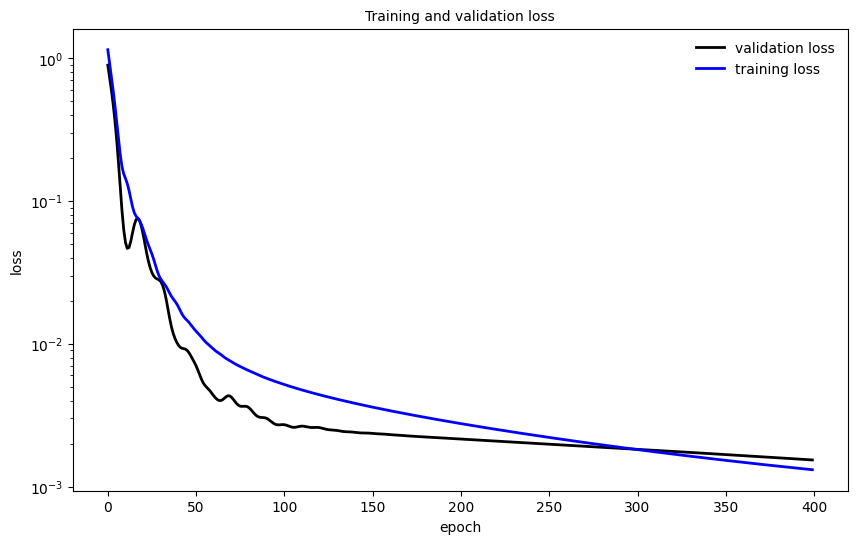

In [12]:
# Prepare dictionary for saving in .mat format
ablation_mat = {}

# Flatten the ablation_results list into a structured dict
for i, result in enumerate(ablation_results):
    ablation_mat[f'result_{i}'] = {
        'idx': result['idx'],
        'neurons_output_layer': result['neurons output layer'],
        'neurons_hidden_per_layer': result['neurons hidden per layer'],
        'hidden_layers': result['hidden layers'],
        'train_loss': np.array(result['training loss']),
        'val_loss': np.array(result['validation loss']),
        'T_train': np.array(result['training time'])
    }

# Save the structured dict to a .mat file
savemat("data_MS/ablation_results.mat", ablation_mat)

# Make figure
plt.figure(figsize=(10, 6))
for i in range(len(ablation_mat)):
    plt.subplot(len(ablation_mat), 1, i+1)
    plt.semilogy(ablation_mat[f'result_{i}']['val_loss'], '-k', lw=2.0, label="validation loss")
    plt.semilogy(ablation_mat[f'result_{i}']['train_loss'], '-b', lw=2.0, label="training loss")
    plt.xlabel('epoch')
    plt.ylabel('loss')
    plt.legend(frameon=False, loc = 'best')
    
plt.title('Training and validation loss', fontsize = 10)    


### Perform MS-DeepONet based MPC simulation

i = 0 / 780

******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit https://github.com/coin-or/Ipopt
******************************************************************************

i = 1 / 780
i = 2 / 780
i = 3 / 780
i = 4 / 780
i = 5 / 780
i = 6 / 780
i = 7 / 780
i = 8 / 780
i = 9 / 780
i = 10 / 780
i = 11 / 780
i = 12 / 780
i = 13 / 780
i = 14 / 780
i = 15 / 780
i = 16 / 780
i = 17 / 780
i = 18 / 780
i = 19 / 780
i = 20 / 780
i = 21 / 780
i = 22 / 780
i = 23 / 780
i = 24 / 780
i = 25 / 780
i = 26 / 780
i = 27 / 780
i = 28 / 780
i = 29 / 780
i = 30 / 780
i = 31 / 780
i = 32 / 780
i = 33 / 780
i = 34 / 780
i = 35 / 780
i = 36 / 780
i = 37 / 780
i = 38 / 780
i = 39 / 780
i = 40 / 780
i = 41 / 780
i = 42 / 780
i = 43 / 780
i = 44 / 780
i = 45 / 780
i = 46 / 780
i = 47 / 780

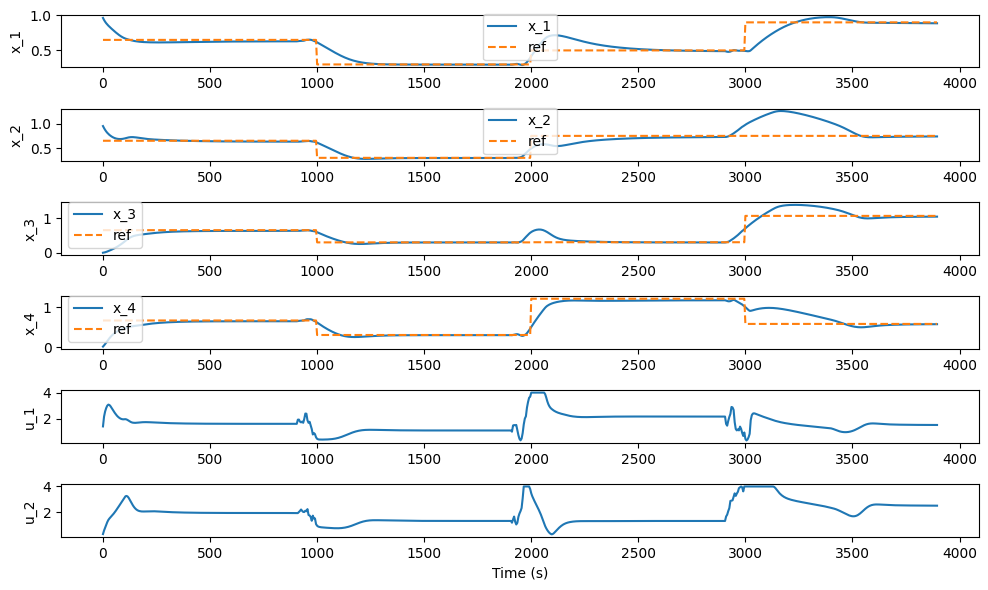

In [ ]:
# select optimal index based on the minimal validation loss in ablation_results:
idx_opt = 1 # change to correct index as defined in the code block: Train the MS-DeepONet model 
branch = torch.load("data_MS/kan_mlp_branch_idx_{}".format(str(int(idx_opt))), map_location=torch.device('cpu'), weights_only=False)
trunk = torch.load("data_MS/kan_mlp_trunk_idx_{}".format(str(int(idx_opt))), map_location=torch.device('cpu'), weights_only=False)

# Network dimensions
ld = 20 # Select here correct number of neurons in output layer of model with index idx_opt

# System dimensions 4tank system
nx = 4  # [h1, h2, h3, h4]
ny = 4  # [h1, h2, h3, h4]
nu = 2  # [u1, u2]

# MPC cost function matrices
Q = np.eye(N*ny) * 100
R = np.eye(N * nu)

# Define constant pieces for reference signal
ref1 = np.tile([0.650, 0.650, 0.652, 0.664], (200, 1))
ref2 = np.tile([0.300, 0.300, 0.301, 0.306], (200, 1))
ref3 = np.tile([0.500, 0.750, 0.305, 1.200], (200, 1))
ref4 = np.tile([0.900, 0.750, 1.062, 0.579], (200, 1))

# Concatenate them along the first axis (time steps)
xref_traj = np.concatenate((ref1, ref2,ref3,ref4), axis=0)  # Shape (100, 2)

# Set up optimization problem
opti = ca.Opti()
y = opti.variable(ny*N,)
u = opti.variable(nu*N,)
du = opti.variable(nu*N,)
x0 = opti.parameter(nx)
u0 = opti.parameter(nu,)
ref = opti.parameter(ny*N,)

# Define cost function
cost = ca.mtimes([(y-ref).T, Q, (y-ref)]) + ca.mtimes([du.T, R, du])

# Neural network predictions
b_out = ca.reshape(NN(u, branch, np.tanh), ld, N*ny)
t_out = NN(x0, trunk, np.tanh)
    
# Define constrains for the MPC problem
opti.subject_to(y == b_out.T@t_out)
opti.subject_to(du[0:nu] == u[0:nu] - u0)
opti.subject_to(du[nu:] == u[nu:] - u[:-nu])
opti.subject_to(opti.bounded(0, u, 4.0))     # input bounds

# Define optimization problem
opti.minimize(cost)

# Solver options 
opti.solver('ipopt', {
    'ipopt.print_level': 0,
    'print_time': 0
    })


x_vals = [] # Initialize empty list for storing state data
u_vals = [] # Initialize empty list for storing input data
solve_times = []  # Initialize empty list to store time per control action 

x_current = np.array([1, 1, 0, 0])  # Initial conditions for 4tank system
u_mpc = np.array([0,0]) # Initial condition for inut (needed for \delta u(0))

# Warm start for input sequence at k=0
previous_u_guess = np.zeros(nu*N)
previous_du_guess = np.zeros(nu*N)

# Start of the simulation loop
for i in range(len(xref_traj)-N):
    print(f'i = {i} / {len(xref_traj)-N}') # Print progress simulation 
    REF = xref_traj[i,:]
    for j in range(N-1):
        REF = np.hstack((REF,xref_traj[i+j,:])) # Define current reference signal 

    opti.set_value(x0, x_current) # Set initial condition
    opti.set_value(u0, u_mpc) # set initial input (u_{k-1})
    opti.set_value(ref, REF) # set reference signal 

    # Warm start
    opti.set_initial(u, previous_u_guess)
    opti.set_initial(du, previous_du_guess)
    
    start = time.perf_counter() # initialize counter
    sol = opti.solve() # solve MPC problem
    elapsed = time.perf_counter() - start # store required time for solving MPC problem
    solve_times.append(elapsed)  # Store each solve time 

    # Update initial guess for warm start
    previous_u_guess = sol.value(u)
    previous_u_guess = np.concatenate([previous_u_guess[nu:], previous_u_guess[-nu:]])
    previous_du_guess = sol.value(du)
    previous_du_guess = np.concatenate([previous_du_guess[nu:], previous_du_guess[-nu:]])

    u_mpc = sol.value(u[0:nu]) # Extract current input, to be applied to the system 
    
    # Apply input to 4tank and simulate for Ts seconds
    sol = solve_ivp(lambda t, x: four_tank(t, x, u_mpc[0], u_mpc[1], params), [0, Ts], x_current)

    # Take the last value as the new initial condition
    x_next = sol.y[:, -1] # measured state at t = (i+1)T_s
    x_vals.append(x_next) # Append state data vector
    u_vals.append(u_mpc) # Append input data vector
    x_current = x_next # Initialize new current state for next iteration 

solve_times = np.array(solve_times) # Convert control times to numpy array 
x_vals = np.array(x_vals) # Convert state data to numpy array 
u_vals = np.array(u_vals) # Convert input data to numpy array 
t_vec = np.arange(len(xref_traj)-N) * Ts # Define time vector

# Make figure of the closed--loop response
plt.figure(figsize=(10, 6))
for i in range(4):
    plt.subplot(6, 1, i+1)
    plt.plot(t_vec, x_vals[:, i], label=f'x_{i+1}')
    plt.plot(t_vec, xref_traj[:len(x_vals), i], '--', label='ref')
    plt.ylabel(f'x_{i+1}')
    plt.legend()
plt.subplot(6, 1, 5)
plt.plot(t_vec, u_vals[:,0])
plt.ylabel('u_1')
plt.subplot(6, 1, 6)
plt.plot(t_vec, u_vals[:,1])
plt.ylabel('u_2')
plt.xlabel('Time (s)')
plt.tight_layout()
plt.show()

## save MPC results a .mat files for analysis in Matlab

In [14]:
# Put them in a dictionary with variable names
data_to_save = {
    "x_vals_MS": x_vals,
    "u_vals_MS": u_vals,
    "solve_times_MS": solve_times,
    "xref_traj_MS": xref_traj    
}

# Save to a .mat file
savemat('data_MS/MS_4tank.mat', data_to_save)
print("Arrays saved to 'MS_4tank.mat'")



Arrays saved to 'MS_4tank.mat'
